<a href="https://colab.research.google.com/github/Rutik28/CDAC-Projects/blob/main/StreamBharat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
!pip install -q pyspark

In [5]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window

spark = (
    SparkSession.builder
    .appName("StreamBharat")
    .master("local[*]")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.sql.adaptive.enabled", "true")
    .getOrCreate()
)

print("Spark version:", spark.version)

Spark version: 4.0.4


In [7]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
BASE = "/content/drive/MyDrive/StreamBharat"

print(os.listdir(BASE))

['data']


In [14]:
import os
from collections import Counter

required = [
    "playback_",
    "catalog_",
    "subscription_events",
    "plans.csv",
    "akashcdn",
    "nimbusedge",
    "cdn_edges.csv",
    "cdn_rates.csv"
]

found = {key: [] for key in required}

for root, dirs, files in os.walk(BASE):
    for filename in files:
        for key in required:
            if key in filename:
                found[key].append(
                    os.path.join(root, filename)
                )

for key, paths in found.items():
    print(f"{key}: {len(paths)} file(s)")
    for path in paths[:3]:
        print(" ", path)

playback_: 126 file(s)
  /content/drive/MyDrive/StreamBharat/data/raw/player/playback_2026-08-13.json
  /content/drive/MyDrive/StreamBharat/data/raw/player/playback_2026-08-12.json
  /content/drive/MyDrive/StreamBharat/data/raw/player/playback_2026-08-11.json
catalog_: 6 file(s)
  /content/drive/MyDrive/StreamBharat/data/raw/content/catalog_2026-07-01.json
  /content/drive/MyDrive/StreamBharat/data/raw/content/catalog_2026-06-01.json
  /content/drive/MyDrive/StreamBharat/data/raw/content/catalog_2026-10-01.json
subscription_events: 1 file(s)
  /content/drive/MyDrive/StreamBharat/data/raw/billing/subscription_events.json
plans.csv: 1 file(s)
  /content/drive/MyDrive/StreamBharat/data/raw/reference/plans.csv
akashcdn: 1 file(s)
  /content/drive/MyDrive/StreamBharat/data/raw/cdn/akashcdn_2026-09.log
nimbusedge: 1 file(s)
  /content/drive/MyDrive/StreamBharat/data/raw/cdn/nimbusedge_2026-09.tsv
cdn_edges.csv: 1 file(s)
  /content/drive/MyDrive/StreamBharat/data/raw/reference/cdn_edges.csv


In [11]:
!pip install -q pyspark

In [12]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window

spark = (
    SparkSession.builder
    .appName("StreamBharat")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.sql.adaptive.enabled", "true")
    .getOrCreate()
)

print(spark.version)

4.0.4


Q2. Clean playback events and correct device clocks
Introduction: Produce reliable event timestamps despite duplicate events, incorrect device clocks and late offline uploads.


In [15]:
playback_files = found["playback_"]

if not playback_files:
    raise FileNotFoundError("No playback files found")

playback = spark.read.json(playback_files)

playback.printSchema()
playback.show(5, truncate=False)

print("Total playback events:", playback.count())

root
 |-- app_version: string (nullable = true)
 |-- client_ts: string (nullable = true)
 |-- content_id: string (nullable = true)
 |-- device_id: string (nullable = true)
 |-- device_type: string (nullable = true)
 |-- download_id: string (nullable = true)
 |-- event_id: string (nullable = true)
 |-- event_type: string (nullable = true)
 |-- ip_city: string (nullable = true)
 |-- position_sec: long (nullable = true)
 |-- profile_id: string (nullable = true)
 |-- server_ts: string (nullable = true)
 |-- user_id: string (nullable = true)

+-----------+-------------------+----------+----------+-----------+-----------+-----------+----------+-------+------------+----------+-------------------+-------+
|app_version|client_ts          |content_id|device_id |device_type|download_id|event_id   |event_type|ip_city|position_sec|profile_id|server_ts          |user_id|
+-----------+-------------------+----------+----------+-----------+-----------+-----------+----------+-------+------------+-------

In [16]:
total_events = playback.count()

unique_events = (
    playback
    .select("event_id")
    .distinct()
    .count()
)

duplicate_events = total_events - unique_events

print("Total events:", total_events)
print("Unique events:", unique_events)
print("Duplicate events:", duplicate_events)

Total events: 1621902
Unique events: 1612215
Duplicate events: 9687


In [17]:
w = Window.partitionBy("event_id").orderBy(
    F.col("server_ts").asc_nulls_last()
)

playback_clean = (
    playback
    .withColumn("row_num", F.row_number().over(w))
    .filter(F.col("row_num") == 1)
    .drop("row_num")
)

print("Clean playback events:", playback_clean.count())

Clean playback events: 1612215


In [18]:
playback_clean = (
    playback_clean
    .withColumn(
        "client_time",
        F.to_timestamp("client_ts")
    )
    .withColumn(
        "server_time",
        F.to_timestamp("server_ts")
    )
)

playback_clean.select(
    "event_id",
    "device_id",
    "client_time",
    "server_time"
).show(10, truncate=False)

+-----------+----------+-------------------+-------------------+
|event_id   |device_id |client_time        |server_time        |
+-----------+----------+-------------------+-------------------+
|E0000000001|DV40747610|2026-07-01 18:59:26|2026-07-01 18:59:29|
|E0000000003|DV40747610|2026-07-01 19:09:27|2026-07-01 19:09:26|
|E0000000007|DV40747610|2026-07-01 19:29:24|2026-07-01 19:29:26|
|E0000000012|DV61877357|2026-07-01 22:05:18|2026-07-01 22:05:22|
|E0000000018|DV61877357|2026-07-01 22:35:21|2026-07-01 22:35:19|
|E0000000020|DV61877357|2026-07-01 22:45:19|2026-07-01 22:45:19|
|E0000000021|DV61877357|2026-07-01 22:50:19|2026-07-01 22:50:20|
|E0000000024|DV61877357|2026-07-01 23:00:18|2026-07-01 23:00:22|
|E0000000033|DV99413605|2026-07-01 18:32:41|2026-07-01 18:32:42|
|E0000000036|DV73245744|2026-07-01 21:29:29|2026-07-01 21:29:30|
+-----------+----------+-------------------+-------------------+
only showing top 10 rows


In [19]:
playback_clean = playback_clean.withColumn(
    "clock_offset_min",
    (
        F.unix_timestamp("server_time")
        - F.unix_timestamp("client_time")
    ) / 60
)

suspicious_events = playback_clean.filter(
    F.abs(F.col("clock_offset_min")) > 10
)

print("Events with offsets greater than 10 minutes:",
      suspicious_events.count())

suspicious_events.select(
    "device_id",
    "client_time",
    "server_time",
    "clock_offset_min"
).show(10, truncate=False)

Events with offsets greater than 10 minutes: 90530
+----------+-------------------+-------------------+-------------------+
|device_id |client_time        |server_time        |clock_offset_min   |
+----------+-------------------+-------------------+-------------------+
|DV81729512|2026-07-01 22:05:21|2026-07-07 08:05:23|7800.033333333334  |
|DV81729512|2026-07-01 22:10:23|2026-07-07 08:10:23|7800.0             |
|DV81729512|2026-07-01 22:25:21|2026-07-07 08:25:23|7800.033333333334  |
|DV81729512|2026-07-01 22:30:25|2026-07-07 08:30:23|7799.966666666666  |
|DV92736757|2026-07-01 03:31:51|2026-07-01 04:31:49|59.96666666666667  |
|DV92736757|2026-07-01 03:36:48|2026-07-01 04:36:49|60.016666666666666 |
|DV92736757|2026-07-01 03:51:50|2026-07-01 04:51:50|60.0               |
|DV92736757|2026-07-01 04:22:13|2026-07-01 05:22:17|60.06666666666667  |
|DV05350345|2026-07-02 01:27:43|2026-07-01 19:27:42|-360.01666666666665|
|DV05350345|2026-07-02 01:37:39|2026-07-01 19:37:44|-359.9166666666667 |


In [20]:
offline_events = playback_clean.filter(
    F.col("download_id").isNotNull()
)

online_events = playback_clean.filter(
    F.col("download_id").isNull()
)

print("Offline events:", offline_events.count())
print("Online events:", online_events.count())

Offline events: 41764
Online events: 1570451


In [21]:
OUTPUT = "/content/drive/MyDrive/StreamBharat/output"

playback_clean.write.mode("overwrite").parquet(
    f"{OUTPUT}/playback_deduplicated"
)

In [22]:
from pyspark.sql import functions as F

online_offsets = (
    playback_clean
    .filter(F.col("download_id").isNull())
    .filter(
        F.col("client_time").isNotNull() &
        F.col("server_time").isNotNull()
    )
    .withColumn(
        "offset_seconds",
        F.unix_timestamp("server_time") -
        F.unix_timestamp("client_time")
    )
)

device_offsets = (
    online_offsets
    .groupBy("device_id")
    .agg(
        F.expr(
            "percentile_approx(offset_seconds, 0.5)"
        ).alias("median_offset_seconds"),
        F.count("*").alias("sample_count")
    )
)

device_offsets.show(10, truncate=False)

+----------+---------------------+------------+
|device_id |median_offset_seconds|sample_count|
+----------+---------------------+------------+
|DV00005558|1                    |242         |
|DV00054335|1                    |287         |
|DV00080373|1                    |635         |
|DV00086414|2                    |251         |
|DV00091295|1                    |136         |
|DV00151008|2                    |439         |
|DV00160237|1                    |303         |
|DV00197925|1                    |61          |
|DV00243726|31536002             |121         |
|DV00259252|1                    |100         |
+----------+---------------------+------------+
only showing top 10 rows


In [23]:
suspicious_devices = (
    device_offsets
    .filter(F.abs(F.col("median_offset_seconds")) > 600)
    .orderBy(F.desc(F.abs(F.col("median_offset_seconds"))))
)

print("Devices with clock offsets greater than 10 minutes:",
      suspicious_devices.count())

suspicious_devices.show(20, truncate=False)

Devices with clock offsets greater than 10 minutes: 111
+----------+---------------------+------------+
|device_id |median_offset_seconds|sample_count|
+----------+---------------------+------------+
|DV00243726|31536002             |121         |
|DV00896302|31536002             |170         |
|DV29544687|31536002             |668         |
|DV44624234|31536002             |197         |
|DV66942553|31536002             |226         |
|DV70288859|31536002             |127         |
|DV14680381|31536001             |122         |
|DV05254895|31536001             |102         |
|DV13096786|31536001             |149         |
|DV24439133|31536001             |108         |
|DV28871696|31536001             |378         |
|DV71395478|31536001             |169         |
|DV64048573|31536001             |171         |
|DV75432609|31536001             |417         |
|DV02533285|-31535999            |226         |
|DV26643901|-31535999            |330         |
|DV27640927|-31535999           

In [24]:
playback_corrected = (
    playback_clean
    .join(
        device_offsets.select(
            "device_id",
            "median_offset_seconds",
            "sample_count"
        ),
        on="device_id",
        how="left"
    )
    .withColumn(
        "corrected_time",
        F.when(
            F.col("median_offset_seconds").isNotNull(),
            F.expr(
                "timestamp_seconds("
                "unix_timestamp(client_time) + median_offset_seconds)"
            )
        ).otherwise(F.col("client_time"))
    )
)

In [25]:
playback_corrected.select(
    "device_id",
    "client_time",
    "server_time",
    "median_offset_seconds",
    "corrected_time"
).show(10, truncate=False)

+----------+-------------------+-------------------+---------------------+-------------------+
|device_id |client_time        |server_time        |median_offset_seconds|corrected_time     |
+----------+-------------------+-------------------+---------------------+-------------------+
|DV19797499|2026-07-02 00:04:03|2026-07-02 00:04:03|2                    |2026-07-02 00:04:05|
|DV40747610|2026-07-01 18:59:26|2026-07-01 18:59:29|1                    |2026-07-01 18:59:27|
|DV40747610|2026-07-01 19:09:27|2026-07-01 19:09:26|1                    |2026-07-01 19:09:28|
|DV40747610|2026-07-01 19:29:24|2026-07-01 19:29:26|1                    |2026-07-01 19:29:25|
|DV40747610|2026-07-01 19:04:28|2026-07-01 19:04:28|1                    |2026-07-01 19:04:29|
|DV40747610|2026-07-01 19:14:27|2026-07-01 19:14:26|1                    |2026-07-01 19:14:28|
|DV40747610|2026-07-01 19:19:24|2026-07-01 19:19:28|1                    |2026-07-01 19:19:25|
|DV40747610|2026-07-01 19:24:28|2026-07-01 19:24:2

In [26]:
playback_corrected = (
    playback_corrected
    .withColumn(
        "arrival_delay_days",
        (
            F.unix_timestamp("server_time") -
            F.unix_timestamp("corrected_time")
        ) / 86400.0
    )
    .withColumn(
        "is_offline",
        F.col("download_id").isNotNull()
    )
)

late_offline = (
    playback_corrected
    .filter(
        F.col("is_offline") &
        (F.col("arrival_delay_days") > 1)
    )
)

print("Offline events arriving more than one day late:",
      late_offline.count())

late_offline.select(
    "event_id",
    "device_id",
    "download_id",
    "corrected_time",
    "server_time",
    "arrival_delay_days"
).show(10, truncate=False)

Offline events arriving more than one day late: 41103
+-----------+----------+-----------+-------------------+-------------------+------------------+
|event_id   |device_id |download_id|corrected_time     |server_time        |arrival_delay_days|
+-----------+----------+-----------+-------------------+-------------------+------------------+
|E0000240550|DV00591529|DL315002009|2026-07-21 23:24:56|2026-07-23 07:24:57|1.3333449074074073|
|E0000240551|DV00591529|DL315002009|2026-07-21 23:29:56|2026-07-23 07:29:57|1.3333449074074073|
|E0000240553|DV00591529|DL315002009|2026-07-21 23:39:58|2026-07-23 07:39:57|1.3333217592592592|
|E0000240557|DV00591529|DL315002009|2026-07-22 00:00:00|2026-07-23 07:59:57|1.3332986111111111|
|E0001344238|DV00591529|DL487347888|2026-10-11 11:25:40|2026-10-14 11:25:41|3.0000115740740743|
|E0001344239|DV00591529|DL487347888|2026-10-11 11:30:43|2026-10-14 11:30:41|2.999976851851852 |
|E0001344240|DV00591529|DL487347888|2026-10-11 11:35:42|2026-10-14 11:35:41|2.9999

In [27]:
playback_corrected = (
    playback_corrected
    .withColumn(
        "playback_date",
        F.to_date("corrected_time")
    )
    .withColumn(
        "arrival_date",
        F.to_date("server_time")
    )
)

playback_corrected.groupBy(
    "playback_date"
).count().orderBy(
    "playback_date"
).show(20)

+-------------+-----+
|playback_date|count|
+-------------+-----+
|   2026-07-01|10387|
|   2026-07-02|11460|
|   2026-07-03|10740|
|   2026-07-04|12338|
|   2026-07-05|13281|
|   2026-07-06|11327|
|   2026-07-07|11276|
|   2026-07-08|10361|
|   2026-07-09|10737|
|   2026-07-10|10680|
|   2026-07-11|13612|
|   2026-07-12|12944|
|   2026-07-13|10403|
|   2026-07-14|10910|
|   2026-07-15|10802|
|   2026-07-16|11007|
|   2026-07-17|11083|
|   2026-07-18|12568|
|   2026-07-19|12848|
|   2026-07-20|11320|
+-------------+-----+
only showing top 20 rows


In [28]:
print("Total corrected events:", playback_corrected.count())

print(
    "Events with missing corrected timestamps:",
    playback_corrected.filter(
        F.col("corrected_time").isNull()
    ).count()
)

playback_corrected.write.mode("overwrite").parquet(
    f"{OUTPUT}/playback_corrected"
)

print("Q2 corrected dataset saved successfully!")

Total corrected events: 1612215
Events with missing corrected timestamps: 0
Q2 corrected dataset saved successfully!


Q5. Viewing sessions and watch time
Introduction: Calculate actual viewing time, excluding pauses, skipped scenes and implausibly long playback.


In [29]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window

playback = spark.read.parquet(
    f"{OUTPUT}/playback_corrected"
)

print("Total events:", playback.count())
playback.printSchema()

playback.select(
    "user_id",
    "profile_id",
    "device_id",
    "content_id",
    "event_type",
    "position_sec",
    "corrected_time"
).show(10, truncate=False)

Total events: 1612215
root
 |-- device_id: string (nullable = true)
 |-- app_version: string (nullable = true)
 |-- client_ts: string (nullable = true)
 |-- content_id: string (nullable = true)
 |-- device_type: string (nullable = true)
 |-- download_id: string (nullable = true)
 |-- event_id: string (nullable = true)
 |-- event_type: string (nullable = true)
 |-- ip_city: string (nullable = true)
 |-- position_sec: long (nullable = true)
 |-- profile_id: string (nullable = true)
 |-- server_ts: string (nullable = true)
 |-- user_id: string (nullable = true)
 |-- client_time: timestamp (nullable = true)
 |-- server_time: timestamp (nullable = true)
 |-- clock_offset_min: double (nullable = true)
 |-- median_offset_seconds: long (nullable = true)
 |-- sample_count: long (nullable = true)
 |-- corrected_time: timestamp (nullable = true)
 |-- arrival_delay_days: double (nullable = true)
 |-- is_offline: boolean (nullable = true)
 |-- playback_date: date (nullable = true)
 |-- arrival_date

In [30]:
playback.groupBy("event_type") \
    .count() \
    .orderBy(F.desc("count")) \
    .show()

+----------+-------+
|event_type|  count|
+----------+-------+
| heartbeat|1236978|
|     start| 169598|
|      stop| 111781|
|     pause|  38595|
|      seek|  36041|
|  complete|  19222|
+----------+-------+



In [31]:
session_keys = [
    "user_id",
    "profile_id",
    "device_id",
    "content_id",
    "download_id"
]

# Window partitioning handles null download IDs
w = Window.partitionBy(*session_keys).orderBy(
    "corrected_time", "event_id"
)

events = (
    playback
    .filter(F.col("corrected_time").isNotNull())
    .withColumn("previous_time", F.lag("corrected_time").over(w))
    .withColumn("previous_event", F.lag("event_type").over(w))
    .withColumn(
        "gap_seconds",
        F.unix_timestamp("corrected_time")
        - F.unix_timestamp("previous_time")
    )
    .withColumn(
        "new_session",
        F.when(F.col("previous_time").isNull(), 1)
         .when(F.col("gap_seconds") > 1800, 1)
         .when(F.col("gap_seconds") < 0, 1)
         .when(F.col("previous_event").isin("stop", "complete"), 1)
         .when(F.col("event_type") == "start", 1)
         .otherwise(0)
    )
)

events = events.withColumn(
    "session_number",
    F.sum("new_session").over(
        w.rowsBetween(Window.unboundedPreceding, Window.currentRow)
    )
)

events = events.withColumn(
    "session_id",
    F.sha2(
        F.concat_ws(
            "|",
            *[F.coalesce(F.col(c).cast("string"), F.lit("NULL"))
              for c in session_keys],
            F.col("session_number").cast("string")
        ),
        256
    )
)

events.select(
    "user_id", "content_id", "event_type",
    "corrected_time", "gap_seconds", "session_id"
).show(10, truncate=False)

+-------+----------+----------+-------------------+-----------+----------------------------------------------------------------+
|user_id|content_id|event_type|corrected_time     |gap_seconds|session_id                                                      |
+-------+----------+----------+-------------------+-----------+----------------------------------------------------------------+
|U000001|CNT00105  |start     |2026-10-11 20:24:52|NULL       |7aee1263a9f5ff1359a405ad11d4690d27c9ffbe2fb9519fecd1291bd1bbd1f8|
|U000001|CNT00105  |heartbeat |2026-10-11 20:29:52|300        |7aee1263a9f5ff1359a405ad11d4690d27c9ffbe2fb9519fecd1291bd1bbd1f8|
|U000001|CNT00105  |heartbeat |2026-10-11 20:34:51|299        |7aee1263a9f5ff1359a405ad11d4690d27c9ffbe2fb9519fecd1291bd1bbd1f8|
|U000001|CNT00105  |heartbeat |2026-10-11 20:39:54|303        |7aee1263a9f5ff1359a405ad11d4690d27c9ffbe2fb9519fecd1291bd1bbd1f8|
|U000001|CNT00105  |heartbeat |2026-10-11 20:44:50|296        |7aee1263a9f5ff1359a405ad11d4690d27

In [32]:
session_window = Window.partitionBy("session_id").orderBy(
    "corrected_time", "event_id"
)

events = (
    events
    .withColumn(
        "prev_position",
        F.lag("position_sec").over(session_window)
    )
    .withColumn(
        "prev_event",
        F.lag("event_type").over(session_window)
    )
    .withColumn(
        "prev_time",
        F.lag("corrected_time").over(session_window)
    )
    .withColumn(
        "elapsed_seconds",
        F.unix_timestamp("corrected_time")
        - F.unix_timestamp("prev_time")
    )
    .withColumn(
        "position_progress",
        F.col("position_sec") - F.col("prev_position")
    )
)

events = events.withColumn(
    "watch_seconds",
    F.when(
        (F.col("event_type").isin("heartbeat", "pause", "stop", "complete")) &
        (F.col("prev_event").isin("start", "heartbeat", "seek")) &
        (F.col("elapsed_seconds") > 0) &
        (F.col("elapsed_seconds") <= 600) &
        (F.col("position_progress") > 0),
        F.least(
            F.col("position_progress"),
            F.col("elapsed_seconds"),
            F.lit(300)
        )
    ).otherwise(F.lit(0))
)

events.select(
    "session_id",
    "event_type",
    "elapsed_seconds",
    "position_progress",
    "watch_seconds"
).show(15, truncate=False)

+----------------------------------------------------------------+----------+---------------+-----------------+-------------+
|session_id                                                      |event_type|elapsed_seconds|position_progress|watch_seconds|
+----------------------------------------------------------------+----------+---------------+-----------------+-------------+
|000040704daabf4612a705d0862e4cc33f1a0416bb51251251e1248c74246e62|start     |NULL           |NULL             |0            |
|000040704daabf4612a705d0862e4cc33f1a0416bb51251251e1248c74246e62|heartbeat |301            |300              |300          |
|000040704daabf4612a705d0862e4cc33f1a0416bb51251251e1248c74246e62|heartbeat |296            |300              |296          |
|000040704daabf4612a705d0862e4cc33f1a0416bb51251251e1248c74246e62|heartbeat |304            |300              |300          |
|000040704daabf4612a705d0862e4cc33f1a0416bb51251251e1248c74246e62|stop      |296            |300              |296    

In [33]:
sessions = (
    events
    .groupBy(
        "session_id",
        "user_id",
        "profile_id",
        "device_id",
        "content_id"
    )
    .agg(
        F.min("corrected_time").alias("session_start"),
        F.max("corrected_time").alias("session_end"),
        F.sum("watch_seconds").alias("watch_seconds"),
        F.max(
            F.when(F.col("event_type") == "complete", 1)
             .otherwise(0)
        ).alias("has_complete_event"),
        F.max("position_sec").alias("max_position_sec"),
        F.count("*").alias("event_count")
    )
    .withColumn(
        "watch_minutes",
        F.round(F.col("watch_seconds") / 60, 2)
    )
)

print("Total viewing sessions:", sessions.count())

sessions.show(10, truncate=False)

Total viewing sessions: 212847
+----------------------------------------------------------------+-------+----------+----------+----------+-------------------+-------------------+-------------+------------------+----------------+-----------+-------------+
|session_id                                                      |user_id|profile_id|device_id |content_id|session_start      |session_end        |watch_seconds|has_complete_event|max_position_sec|event_count|watch_minutes|
+----------------------------------------------------------------+-------+----------+----------+----------+-------------------+-------------------+-------------+------------------+----------------+-----------+-------------+
|000040704daabf4612a705d0862e4cc33f1a0416bb51251251e1248c74246e62|U001358|U001358-P1|DV16690785|CNT00069  |2026-07-25 15:46:28|2026-07-25 16:06:25|1192         |0                 |2812            |5          |19.87        |
|00009fdb836e99f745b56441b43ac6ce0c49e9468418845e7a75b20fea9a8f1c|U002041

In [34]:
catalog = (
    spark.read
    .option("multiLine", "true")
    .json(found["catalog_"])
)

movies_live = (
    catalog
    .filter(F.col("type").isin("movie", "live"))
    .select(
        "content_id",
        "title",
        "type",
        "duration_sec"
    )
)

episodes = (
    catalog
    .filter(F.col("type") == "series")
    .select(
        F.col("title").alias("series_title"),
        F.explode_outer("seasons").alias("season")
    )
    .select(
        "series_title",
        F.explode_outer("season.episodes").alias("episode")
    )
    .select(
        F.col("episode.content_id").alias("content_id"),
        F.concat_ws(
            " - ",
            F.col("series_title"),
            F.col("episode.title")
        ).alias("title"),
        F.lit("episode").alias("type"),
        F.col("episode.duration_sec").alias("duration_sec")
    )
)

content_lookup = (
    movies_live
    .unionByName(episodes)
    .dropDuplicates(["content_id"])
)

content_lookup.show(10, truncate=False)

+----------+----------------+-------+------------+
|content_id|title           |type   |duration_sec|
+----------+----------------+-------+------------+
|NULL      |Dharavi Nights  |episode|NULL        |
|CNT00001  |Udaan Sapne     |movie  |8460        |
|CNT00002  |Raasta Toofan   |movie  |8520        |
|CNT00003  |Kahani Gang     |movie  |9180        |
|CNT00004  |Chaand Udaan    |movie  |7800        |
|CNT00005  |Dhoop Files     |movie  |6060        |
|CNT00006  |Dilli Rising    |movie  |7980        |
|CNT00007  |Kinara Club     |movie  |9300        |
|CNT00008  |Barsaat Gang    |movie  |9600        |
|CNT00009  |Sapne Chronicles|movie  |9960        |
+----------+----------------+-------+------------+
only showing top 10 rows


In [35]:
sessions_with_content = sessions.join(
    content_lookup,
    on="content_id",
    how="left"
)

sessions_with_content = (
    sessions_with_content
    .withColumn(
        "completion_percentage",
        F.when(
            F.col("duration_sec") > 0,
            F.round(
                F.col("max_position_sec") /
                F.col("duration_sec") * 100,
                2
            )
        )
    )
    .withColumn(
        "is_completed",
        F.when(
            (F.col("has_complete_event") == 1) |
            (F.col("completion_percentage") >= 90),
            1
        ).otherwise(0)
    )
)

sessions_with_content.select(
    "content_id",
    "title",
    "watch_minutes",
    "completion_percentage",
    "is_completed"
).show(15, truncate=False)

+----------+----------------+-------------+---------------------+------------+
|content_id|title           |watch_minutes|completion_percentage|is_completed|
+----------+----------------+-------------+---------------------+------------+
|CNT00069  |Lehren Lehren   |19.87        |32.55                |0           |
|CNT00116  |Udaan Chronicles|0.0          |22.0                 |0           |
|CNT00195  |Dhoop Chronicles|54.83        |40.74                |0           |
|CNT00039  |Pehchaan Story  |19.92        |14.71                |0           |
|CNT00145  |Mitti Junction  |19.95        |14.18                |0           |
|CNT00133  |Agni Rising     |29.95        |65.25                |0           |
|CNT00041  |Chakra Dilli    |64.78        |58.41                |0           |
|CNT00236  |Raat Gang       |0.0          |51.55                |0           |
|CNT00312  |Khel Barsaat    |101.6        |100.0                |1           |
|CNT00322  |Chaand Toofan   |29.93        |25.42    

In [36]:
catalog = (
    spark.read
    .option("multiLine", "true")
    .json(found["catalog_"])
)

movies_live = (
    catalog
    .filter(F.col("type").isin("movie", "live"))
    .select(
        "content_id",
        "title",
        "type",
        "duration_sec"
    )
)

episodes = (
    catalog
    .filter(F.col("type") == "series")
    .select(
        F.col("title").alias("series_title"),
        F.explode_outer("seasons").alias("season")
    )
    .select(
        "series_title",
        F.explode_outer("season.episodes").alias("episode")
    )
    .select(
        F.col("episode.content_id").alias("content_id"),
        F.concat_ws(
            " - ",
            F.col("series_title"),
            F.col("episode.title")
        ).alias("title"),
        F.lit("episode").alias("type"),
        F.col("episode.duration_sec").alias("duration_sec")
    )
)

content_lookup = (
    movies_live
    .unionByName(episodes)
    .dropDuplicates(["content_id"])
)

content_lookup.show(10, truncate=False)

+----------+----------------+-------+------------+
|content_id|title           |type   |duration_sec|
+----------+----------------+-------+------------+
|NULL      |Dharavi Nights  |episode|NULL        |
|CNT00001  |Udaan Sapne     |movie  |8460        |
|CNT00002  |Raasta Toofan   |movie  |8520        |
|CNT00003  |Kahani Gang     |movie  |9180        |
|CNT00004  |Chaand Udaan    |movie  |7800        |
|CNT00005  |Dhoop Files     |movie  |6060        |
|CNT00006  |Dilli Rising    |movie  |7980        |
|CNT00007  |Kinara Club     |movie  |9300        |
|CNT00008  |Barsaat Gang    |movie  |9600        |
|CNT00009  |Sapne Chronicles|movie  |9960        |
+----------+----------------+-------+------------+
only showing top 10 rows


In [37]:
sessions_with_content = sessions.join(
    content_lookup,
    on="content_id",
    how="left"
)

sessions_with_content = (
    sessions_with_content
    .withColumn(
        "completion_percentage",
        F.when(
            F.col("duration_sec") > 0,
            F.round(
                F.col("max_position_sec") /
                F.col("duration_sec") * 100,
                2
            )
        )
    )
    .withColumn(
        "is_completed",
        F.when(
            (F.col("has_complete_event") == 1) |
            (F.col("completion_percentage") >= 90),
            1
        ).otherwise(0)
    )
)

sessions_with_content.select(
    "content_id",
    "title",
    "watch_minutes",
    "completion_percentage",
    "is_completed"
).show(15, truncate=False)

+----------+----------------+-------------+---------------------+------------+
|content_id|title           |watch_minutes|completion_percentage|is_completed|
+----------+----------------+-------------+---------------------+------------+
|CNT00069  |Lehren Lehren   |19.87        |32.55                |0           |
|CNT00116  |Udaan Chronicles|0.0          |22.0                 |0           |
|CNT00195  |Dhoop Chronicles|54.83        |40.74                |0           |
|CNT00039  |Pehchaan Story  |19.92        |14.71                |0           |
|CNT00145  |Mitti Junction  |19.95        |14.18                |0           |
|CNT00133  |Agni Rising     |29.95        |65.25                |0           |
|CNT00041  |Chakra Dilli    |64.78        |58.41                |0           |
|CNT00236  |Raat Gang       |0.0          |51.55                |0           |
|CNT00312  |Khel Barsaat    |101.6        |100.0                |1           |
|CNT00322  |Chaand Toofan   |29.93        |25.42    

In [38]:
daily_watch_time = (
    sessions_with_content
    .withColumn(
        "watch_date",
        F.to_date("session_start")
    )
    .groupBy("watch_date")
    .agg(
        F.round(
            F.sum("watch_minutes") / 60, 2
        ).alias("watch_hours"),
        F.countDistinct("session_id").alias("total_sessions"),
        F.countDistinct("user_id").alias("active_users")
    )
    .orderBy("watch_date")
)

daily_watch_time.show(20, truncate=False)

+----------+-----------+--------------+------------+
|watch_date|watch_hours|total_sessions|active_users|
+----------+-----------+--------------+------------+
|2026-07-01|673.42     |1423          |664         |
|2026-07-02|682.84     |1527          |667         |
|2026-07-03|656.32     |1477          |668         |
|2026-07-04|760.4      |1685          |768         |
|2026-07-05|809.85     |1776          |802         |
|2026-07-06|688.14     |1530          |667         |
|2026-07-07|698.7      |1554          |707         |
|2026-07-08|645.09     |1422          |642         |
|2026-07-09|660.07     |1440          |646         |
|2026-07-10|669.99     |1413          |651         |
|2026-07-11|842.83     |1793          |838         |
|2026-07-12|787.81     |1732          |793         |
|2026-07-13|642.87     |1405          |619         |
|2026-07-14|685.53     |1524          |681         |
|2026-07-15|665.13     |1460          |677         |
|2026-07-16|666.3      |1429          |658    

In [40]:
sessions_with_content.write.mode("overwrite").parquet(
    f"{OUTPUT}/viewing_sessions"
)

daily_watch_time.write.mode("overwrite").parquet(
    f"{OUTPUT}/daily_watch_time"
)

print("Q5 outputs saved successfully!")

Q5 outputs saved successfully!


Q12. Detect account sharing
Introduction: Identify accounts exceeding their plan's concurrent-screen allowance or showing suspicious simultaneous locations.


In [41]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window

sessions = spark.read.parquet(
    f"{OUTPUT}/viewing_sessions"
)

billing = spark.read.json(
    found["subscription_events"][0]
)

plans = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv(found["plans.csv"][0])
)

print("Sessions:", sessions.count())
print("Billing events:", billing.count())

billing.printSchema()
plans.printSchema()

billing.show(5, truncate=False)
plans.show(truncate=False)

Sessions: 212847
Billing events: 20033
root
 |-- event_ts: string (nullable = true)
 |-- event_type: string (nullable = true)
 |-- gateway: string (nullable = true)
 |-- plan: string (nullable = true)
 |-- price: long (nullable = true)
 |-- user_id: string (nullable = true)

root
 |-- plan: string (nullable = true)
 |-- price_inr_per_month: integer (nullable = true)
 |-- max_screens: integer (nullable = true)

+-------------------+-----------+-----------+-------+-----+-------+
|event_ts           |event_type |gateway    |plan   |price|user_id|
+-------------------+-----------+-----------+-------+-----+-------+
|2025-05-03T00:34:05|trial_start|PlayStore  |premium|0    |U001395|
|2025-05-03T02:44:34|trial_start|PlayStore  |premium|0    |U001051|
|2025-05-03T09:16:29|trial_start|UPI-Autopay|premium|0    |U001466|
|2025-05-03T17:39:05|trial_start|PlayStore  |premium|0    |U002199|
|2025-05-03T21:06:20|trial_start|UPI-Autopay|premium|0    |U000319|
+-------------------+-----------+---------

In [42]:
device_usage = (
    sessions
    .groupBy("user_id")
    .agg(
        F.countDistinct("device_id").alias("total_devices"),
        F.countDistinct("profile_id").alias("total_profiles"),
        F.countDistinct("session_id").alias("total_sessions")
    )
    .orderBy(F.desc("total_devices"))
)

device_usage.show(20, truncate=False)

+-------+-------------+--------------+--------------+
|user_id|total_devices|total_profiles|total_sessions|
+-------+-------------+--------------+--------------+
|U000235|4            |1             |50            |
|U001499|4            |1             |590           |
|U001761|4            |1             |630           |
|U002494|4            |4             |657           |
|U001887|4            |1             |650           |
|U000900|4            |3             |658           |
|U001713|4            |2             |657           |
|U000186|4            |3             |614           |
|U000854|4            |2             |663           |
|U001355|4            |2             |390           |
|U001945|4            |1             |647           |
|U001467|4            |1             |494           |
|U001576|4            |1             |635           |
|U001017|4            |2             |627           |
|U001732|4            |1             |494           |
|U001625|4            |4    

In [43]:
session_activity = (
    sessions
    .withColumn(
        "window_start",
        F.from_unixtime(
            F.floor(F.unix_timestamp("session_start") / 600) * 600
        ).cast("timestamp")
    )
)

concurrent_devices = (
    session_activity
    .groupBy("user_id", "window_start")
    .agg(
        F.countDistinct("device_id").alias("concurrent_devices")
    )
    .filter(F.col("concurrent_devices") >= 3)
    .orderBy(F.desc("concurrent_devices"))
)

concurrent_devices.show(20, truncate=False)

+-------+-------------------+------------------+
|user_id|window_start       |concurrent_devices|
+-------+-------------------+------------------+
|U001675|2026-07-24 21:50:00|4                 |
|U001761|2026-08-10 21:20:00|4                 |
|U001017|2026-07-10 21:10:00|4                 |
|U002348|2026-08-03 22:40:00|4                 |
|U001949|2026-08-24 21:30:00|4                 |
|U001436|2026-08-08 21:10:00|3                 |
|U000816|2026-09-01 21:00:00|3                 |
|U002354|2026-07-22 20:40:00|3                 |
|U001675|2026-09-18 21:00:00|3                 |
|U001598|2026-08-04 22:10:00|3                 |
|U000229|2026-08-29 20:30:00|3                 |
|U001479|2026-10-20 21:10:00|3                 |
|U001770|2026-09-09 22:50:00|3                 |
|U000614|2026-10-07 21:40:00|3                 |
|U001224|2026-08-17 21:40:00|3                 |
|U002348|2026-10-01 22:50:00|3                 |
|U001499|2026-10-20 21:40:00|3                 |
|U001478|2026-10-23 

In [44]:
account_concurrency = (
    concurrent_devices
    .groupBy("user_id")
    .agg(
        F.max("concurrent_devices").alias("max_concurrent_devices"),
        F.count("*").alias("suspicious_windows")
    )
)

account_concurrency.show(20, truncate=False)

+-------+----------------------+------------------+
|user_id|max_concurrent_devices|suspicious_windows|
+-------+----------------------+------------------+
|U001017|4                     |4                 |
|U000900|3                     |3                 |
|U001168|3                     |5                 |
|U002494|3                     |3                 |
|U000186|3                     |2                 |
|U000871|3                     |2                 |
|U002276|3                     |4                 |
|U001761|4                     |4                 |
|U001945|3                     |6                 |
|U001713|3                     |5                 |
|U001887|3                     |3                 |
|U001936|3                     |3                 |
|U000854|3                     |1                 |
|U002354|3                     |4                 |
|U002284|3                     |3                 |
|U000816|3                     |4                 |
|U001576|3  

In [45]:
billing_clean = (
    billing
    .withColumn("event_time", F.to_timestamp("event_ts"))
)

plan_window = (
    Window
    .partitionBy("user_id")
    .orderBy(F.col("event_time").desc())
)

latest_plan = (
    billing_clean
    .filter(F.col("plan").isNotNull())
    .withColumn(
        "rn",
        F.row_number().over(plan_window)
    )
    .filter(F.col("rn") == 1)
    .select(
        "user_id",
        F.col("plan").alias("current_plan")
    )
)

latest_plan.show(10, truncate=False)

+-------+------------+
|user_id|current_plan|
+-------+------------+
|U000002|basic       |
|U000003|premium     |
|U000004|premium     |
|U000005|premium     |
|U000006|basic       |
|U000007|premium     |
|U000008|basic       |
|U000009|basic       |
|U000010|basic       |
|U000012|premium     |
+-------+------------+
only showing top 10 rows


In [46]:
plan_limits = plans.select(
    F.col("plan").alias("current_plan"),
    F.col("max_screens").cast("int").alias("max_screens"),
    F.col("price_inr_per_month").cast("double").alias("monthly_price")
)

account_analysis = (
    device_usage
    .join(account_concurrency, "user_id", "left")
    .join(latest_plan, "user_id", "left")
    .join(plan_limits, "current_plan", "left")
    .fillna({
        "max_concurrent_devices": 0,
        "suspicious_windows": 0
    })
    .withColumn(
        "exceeds_plan_limit",
        F.when(
            F.col("max_concurrent_devices") > F.col("max_screens"),
            1
        ).otherwise(0)
    )
)

account_analysis.select(
    "user_id",
    "current_plan",
    "max_screens",
    "total_devices",
    "max_concurrent_devices",
    "exceeds_plan_limit"
).show(20, truncate=False)

+-------+------------+-----------+-------------+----------------------+------------------+
|user_id|current_plan|max_screens|total_devices|max_concurrent_devices|exceeds_plan_limit|
+-------+------------+-----------+-------------+----------------------+------------------+
|U002278|premium     |4          |3            |0                     |0                 |
|U000023|NULL        |NULL       |1            |0                     |0                 |
|U002142|premium     |4          |2            |0                     |0                 |
|U001873|basic       |2          |1            |0                     |0                 |
|U001020|basic       |2          |1            |0                     |0                 |
|U000867|basic       |2          |1            |0                     |0                 |
|U000739|premium     |4          |3            |0                     |0                 |
|U000554|premium     |4          |2            |0                     |0                 |

In [47]:
account_analysis = (
    account_analysis
    .withColumn(
        "additional_subscriptions",
        F.when(
            (F.col("max_screens") > 0) &
            (F.col("max_concurrent_devices") > F.col("max_screens")),
            F.ceil(
                F.col("max_concurrent_devices") /
                F.col("max_screens")
            ) - 1
        ).otherwise(0)
    )
    .withColumn(
        "potential_monthly_revenue_inr",
        F.col("additional_subscriptions") *
        F.coalesce(F.col("monthly_price"), F.lit(0.0))
    )
)

account_analysis.select(
    "user_id",
    "current_plan",
    "max_concurrent_devices",
    "additional_subscriptions",
    "potential_monthly_revenue_inr"
).orderBy(
    F.desc("potential_monthly_revenue_inr")
).show(20, truncate=False)

+-------+------------+----------------------+------------------------+-----------------------------+
|user_id|current_plan|max_concurrent_devices|additional_subscriptions|potential_monthly_revenue_inr|
+-------+------------+----------------------+------------------------+-----------------------------+
|U000186|basic       |3                     |1                       |149.0                        |
|U000335|basic       |3                     |1                       |149.0                        |
|U002276|basic       |3                     |1                       |149.0                        |
|U001576|basic       |3                     |1                       |149.0                        |
|U002274|basic       |3                     |1                       |149.0                        |
|U000816|basic       |3                     |1                       |149.0                        |
|U001625|basic       |3                     |1                       |149.0                

In [48]:
q12_summary = account_analysis.agg(
    F.count("*").alias("accounts_analyzed"),
    F.sum("exceeds_plan_limit").alias("accounts_exceeding_limit"),
    F.sum("additional_subscriptions").alias("estimated_extra_subscriptions"),
    F.round(
        F.sum("potential_monthly_revenue_inr"), 2
    ).alias("potential_monthly_revenue_inr")
)

q12_summary.show(truncate=False)

+-----------------+------------------------+-----------------------------+-----------------------------+
|accounts_analyzed|accounts_exceeding_limit|estimated_extra_subscriptions|potential_monthly_revenue_inr|
+-----------------+------------------------+-----------------------------+-----------------------------+
|2499             |36                      |36                           |5364.0                       |
+-----------------+------------------------+-----------------------------+-----------------------------+



In [49]:
account_analysis.write.mode("overwrite").parquet(
    f"{OUTPUT}/account_sharing_analysis"
)

q12_summary.write.mode("overwrite").parquet(
    f"{OUTPUT}/q12_summary"
)

print("Q12 outputs saved successfully!")

Q12 outputs saved successfully!


Q14. Handle live-cricket data skew
Introduction: Diagnose and reduce Spark slowdown caused by one content_id dominating playback and CDN data


In [50]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window

playback = spark.read.parquet(
    f"{OUTPUT}/playback_corrected"
)

print("Total playback events:", playback.count())

playback.select(
    "content_id",
    "event_type",
    "corrected_time",
    "playback_date"
).show(5, truncate=False)

Total playback events: 1612215
+----------+----------+-------------------+-------------+
|content_id|event_type|corrected_time     |playback_date|
+----------+----------+-------------------+-------------+
|CNT00057  |heartbeat |2026-07-22 21:28:14|2026-07-22   |
|CNT00057  |heartbeat |2026-07-22 21:53:12|2026-07-22   |
|CNT00057  |heartbeat |2026-07-22 21:33:14|2026-07-22   |
|CNT00116  |heartbeat |2026-07-22 13:12:59|2026-07-22   |
|CNT00057  |heartbeat |2026-07-22 21:43:14|2026-07-22   |
+----------+----------+-------------------+-------------+
only showing top 5 rows


In [51]:
FINAL_DATE = "2026-09-27"
FINAL_CONTENT = "CNT01197"

final_day = playback.filter(
    F.col("playback_date") == FINAL_DATE
)

cricket_final = final_day.filter(
    F.col("content_id") == FINAL_CONTENT
)

total_day_events = final_day.count()
final_events = cricket_final.count()

print("Total events on final day:", total_day_events)
print("Cricket final events:", final_events)

if total_day_events > 0:
    print(
        "Cricket final traffic percentage:",
        round(final_events / total_day_events * 100, 2)
    )

Total events on final day: 45696
Cricket final events: 31966
Cricket final traffic percentage: 69.95


In [52]:
hourly_traffic = (
    final_day
    .withColumn(
        "hour",
        F.hour("corrected_time")
    )
    .groupBy("hour")
    .agg(
        F.count("*").alias("total_events"),
        F.sum(
            F.when(
                F.col("content_id") == FINAL_CONTENT, 1
            ).otherwise(0)
        ).alias("cricket_events")
    )
    .orderBy("hour")
)

hourly_traffic.show(24, truncate=False)

+----+------------+--------------+
|hour|total_events|cricket_events|
+----+------------+--------------+
|0   |610         |0             |
|1   |401         |0             |
|2   |185         |0             |
|3   |138         |0             |
|4   |158         |0             |
|5   |103         |0             |
|6   |181         |0             |
|7   |290         |0             |
|8   |318         |0             |
|9   |291         |0             |
|10  |287         |0             |
|11  |229         |0             |
|12  |318         |0             |
|13  |359         |0             |
|14  |404         |0             |
|15  |346         |0             |
|16  |406         |0             |
|17  |485         |0             |
|18  |786         |1             |
|19  |8917        |8131          |
|20  |12571       |11150         |
|21  |10001       |7980          |
|22  |6025        |4134          |
|23  |1887        |570           |
+----+------------+--------------+



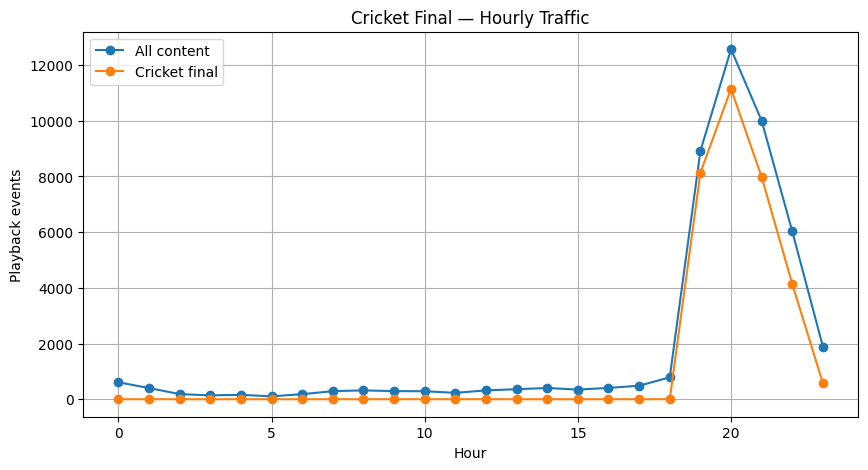

In [53]:
import matplotlib.pyplot as plt

hourly_pd = hourly_traffic.toPandas()

plt.figure(figsize=(10, 5))
plt.plot(
    hourly_pd["hour"],
    hourly_pd["total_events"],
    marker="o",
    label="All content"
)
plt.plot(
    hourly_pd["hour"],
    hourly_pd["cricket_events"],
    marker="o",
    label="Cricket final"
)

plt.xlabel("Hour")
plt.ylabel("Playback events")
plt.title("Cricket Final — Hourly Traffic")
plt.legend()
plt.grid(True)
plt.show()

In [54]:
content_distribution = (
    final_day
    .groupBy("content_id")
    .count()
    .orderBy(F.desc("count"))
)

content_distribution.show(15, truncate=False)

+----------+-----+
|content_id|count|
+----------+-----+
|CNT01197  |31966|
|CNT00116  |1001 |
|CNT00237  |808  |
|CNT00190  |382  |
|CNT00089  |332  |
|CNT00278  |279  |
|CNT00024  |276  |
|CNT00166  |235  |
|CNT00246  |227  |
|CNT00080  |219  |
|CNT00176  |177  |
|CNT00297  |171  |
|CNT00232  |162  |
|CNT00095  |118  |
|CNT00332  |117  |
+----------+-----+
only showing top 15 rows


In [55]:
top_content = content_distribution.first()

if top_content and total_day_events > 0:
    print("Most frequent content:", top_content["content_id"])
    print("Event count:", top_content["count"])
    print(
        "Share of daily traffic:",
        round(top_content["count"] / total_day_events * 100, 2),
        "%"
    )

Most frequent content: CNT01197
Event count: 31966
Share of daily traffic: 69.95 %


In [56]:
salted_events = (
    final_day
    .withColumn(
        "salt",
        F.when(
            F.col("content_id") == FINAL_CONTENT,
            F.pmod(
                F.xxhash64("event_id"),
                F.lit(8)
            )
        ).otherwise(F.lit(0))
    )
)

partial_counts = (
    salted_events
    .groupBy("content_id", "salt")
    .agg(
        F.count("*").alias("partial_count")
    )
)

optimized_counts = (
    partial_counts
    .groupBy("content_id")
    .agg(
        F.sum("partial_count").alias("total_events")
    )
    .orderBy(F.desc("total_events"))
)

optimized_counts.show(15, truncate=False)

+----------+------------+
|content_id|total_events|
+----------+------------+
|CNT01197  |31966       |
|CNT00116  |1001        |
|CNT00237  |808         |
|CNT00190  |382         |
|CNT00089  |332         |
|CNT00278  |279         |
|CNT00024  |276         |
|CNT00166  |235         |
|CNT00246  |227         |
|CNT00080  |219         |
|CNT00176  |177         |
|CNT00297  |171         |
|CNT00232  |162         |
|CNT00095  |118         |
|CNT00332  |117         |
+----------+------------+
only showing top 15 rows


In [78]:
akash_path = found["akashcdn"][0]

akash_raw = spark.read.text(akash_path)

akash = (
    akash_raw
    .withColumn(
        "timestamp_str",
        F.regexp_extract("value", r'^(\S+)', 1)
    )
    .withColumn(
        "edge",
        F.regexp_extract("value", r'^\S+\s+(\S+)', 1)
    )
    .withColumn(
        "request_path",
        F.regexp_extract(
            "value",
            r'"(?:GET|HEAD)\s+(\S+)\s+HTTP/[^"]+"',
            1
        )
    )
    .withColumn(
        "status",
          F.expr("try_cast(regexp_extract(value, '\"\\s+(\\d{3})\\s+', 1) AS INT)")

    )
    .withColumn(
        "bytes",
        F.regexp_extract(
            "value",
            r'"\s+\d{3}\s+(\d+)',
            1
        ).cast("long")
    )
    .withColumn(
        "event_time",
         F.to_timestamp(
            F.col("timestamp_str"),
            "yyyy-MM-dd'T'HH:mm:ssX"
        )
    )
    .withColumn(
        "content_id",
        F.regexp_extract(
            "request_path",
            r'/v/([^/]+)/',
            1
        )
    )
)

akash.select(
    "event_time",
    "edge",
    "content_id",
    "status",
    "bytes"
).show(10, truncate=False)

+-------------------+-----------+----------+------+---------+
|event_time         |edge       |content_id|status|bytes    |
+-------------------+-----------+----------+------+---------+
|2026-09-01 00:04:59|edge-pnq-01|CNT00024  |NULL  |90082159 |
|2026-09-01 00:09:56|edge-pnq-01|CNT00024  |NULL  |107115920|
|2026-09-01 00:03:33|edge-lko-01|CNT00060  |NULL  |177553138|
|2026-09-01 00:08:33|edge-lko-01|CNT00060  |NULL  |165042412|
|2026-09-01 00:13:32|edge-lko-01|CNT00060  |NULL  |104514875|
|2026-09-01 00:18:32|edge-lko-01|CNT00060  |NULL  |38672238 |
|2026-09-01 00:23:31|edge-lko-01|CNT00060  |NULL  |38231116 |
|2026-09-01 00:28:31|edge-lko-01|CNT00060  |NULL  |91715661 |
|2026-09-01 00:33:33|edge-lko-01|CNT00060  |NULL  |93242926 |
|2026-09-01 00:38:33|edge-lko-01|CNT00060  |NULL  |86051595 |
+-------------------+-----------+----------+------+---------+
only showing top 10 rows


In [79]:
nimbus_raw = spark.read.text(nimbus_path)

parts = F.split(F.col("value"), "\t")

nimbus = (
    nimbus_raw
    .withColumn("epoch_seconds", parts.getItem(0))
    .withColumn("edge", parts.getItem(1))
    .withColumn("client_hash", parts.getItem(2))
    .withColumn("request_path", parts.getItem(3))
    .withColumn("status", parts.getItem(4).cast("int"))
    .withColumn("bytes", parts.getItem(5).cast("long"))
    .withColumn("user_agent", parts.getItem(6))
    .withColumn(
        "event_time",
        F.from_unixtime(
            F.col("epoch_seconds").cast("long")
        ).cast("timestamp")
    )
    .withColumn(
        "content_id",
        F.regexp_extract(
            "request_path",
            r'vod/([^/]+)/',
            1
        )
    )
)

In [81]:
from pyspark.sql import functions as F

spark.conf.set("spark.sql.session.timeZone", "UTC")

# -------------------------------
# AKASH CDN
# -------------------------------

akash_raw = spark.read.text(found["akashcdn"][0])

akash = (
    akash_raw
    .withColumn(
        "timestamp_str",
        F.regexp_extract("value", r"^(\S+)", 1)
    )
    .withColumn(
        "edge",
        F.regexp_extract("value", r"^\S+\s+(\S+)", 1)
    )
    .withColumn(
        "request_path",
        F.regexp_extract(
            "value",
            r'"(?:GET|HEAD)\s+(\S+)\s+HTTP/[^"]+"',
            1
        )
    )
    .withColumn(
        "status_text",
        F.regexp_extract(
            "value",
            r'"\s+(\d{3})\s+',
            1
        )
    )
    .withColumn(
        "bytes_text",
        F.regexp_extract(
            "value",
            r'"\s+\d{3}\s+(\d+)',
            1
        )
    )
    .withColumn(
        "status",
        F.expr("try_cast(status_text AS INT)")
    )
    .withColumn(
        "bytes",
        F.expr("try_cast(bytes_text AS BIGINT)")
    )
    .withColumn(
        "event_time",
        F.to_timestamp(
            "timestamp_str",
            "yyyy-MM-dd'T'HH:mm:ssX"
        )
    )
    .withColumn(
        "content_id",
        F.regexp_extract(
            "request_path",
            r"/v/([^/]+)/",
            1
        )
    )
)

# -------------------------------
# NIMBUS EDGE
# -------------------------------

nimbus_raw = spark.read.text(found["nimbusedge"][0])

parts = F.split(F.col("value"), "\t")

nimbus = (
    nimbus_raw
    .withColumn("epoch_text", parts.getItem(0))
    .withColumn("edge", parts.getItem(1))
    .withColumn("request_path", parts.getItem(3))
    .withColumn("status_text", parts.getItem(4))
    .withColumn("bytes_text", parts.getItem(5))
    .withColumn(
        "epoch_seconds",
        F.expr("try_cast(epoch_text AS BIGINT)")
    )
    .withColumn(
        "status",
        F.expr("try_cast(status_text AS INT)")
    )
    .withColumn(
        "bytes",
        F.expr("try_cast(bytes_text AS BIGINT)")
    )
    .withColumn(
        "event_time",
        F.timestamp_seconds("epoch_seconds")
    )
    .withColumn(
        "content_id",
        F.regexp_extract(
            "request_path",
            r"vod/([^/]+)/",
            1
        )
    )
)

# -------------------------------
# COMBINE BOTH CDN DATASETS
# -------------------------------

akash_clean = akash.select(
    F.lit("AkashCDN").alias("cdn"),
    "event_time",
    "edge",
    "content_id",
    "status",
    "bytes"
)

nimbus_clean = nimbus.select(
    F.lit("NimbusEdge").alias("cdn"),
    "event_time",
    "edge",
    "content_id",
    "status",
    "bytes"
)

cdn_all = akash_clean.unionByName(nimbus_clean)

# Remove malformed records
cdn_logs = cdn_all.filter(
    F.col("event_time").isNotNull() &
    F.col("status").isNotNull() &
    F.col("bytes").isNotNull() &
    (F.col("bytes") >= 0) &
    (F.col("content_id") != "")
)

print("CDN records before cleaning:", cdn_all.count())
print("Valid CDN records:", cdn_logs.count())
print("Malformed CDN records:",
      cdn_all.count() - cdn_logs.count())

cdn_logs.groupBy("cdn").count().show()

CDN records before cleaning: 333066
Valid CDN records: 332384
Malformed CDN records: 682
+----------+------+
|       cdn| count|
+----------+------+
|  AkashCDN|166032|
|NimbusEdge|166352|
+----------+------+



In [82]:
cdn_logs.printSchema()

root
 |-- cdn: string (nullable = false)
 |-- event_time: timestamp (nullable = true)
 |-- edge: string (nullable = true)
 |-- content_id: string (nullable = true)
 |-- status: integer (nullable = true)
 |-- bytes: long (nullable = true)



In [84]:
cdn_bandwidth = (
    cdn_logs
    .groupBy("cdn")
    .agg(
        F.count("*").alias("total_requests"),
        F.sum("bytes").alias("total_bytes")
    )
    .withColumn(
        "bandwidth_gb",
        F.round(F.col("total_bytes") / 1000000000, 2)
    )
)

cdn_bandwidth.show(truncate=False)

+----------+--------------+--------------+------------+
|cdn       |total_requests|total_bytes   |bandwidth_gb|
+----------+--------------+--------------+------------+
|AkashCDN  |166032        |18072154371340|18072.15    |
|NimbusEdge|166352        |18071389307125|18071.39    |
+----------+--------------+--------------+------------+



In [85]:
cdn_edges = (
    spark.read
    .option("header", True)
    .csv(found["cdn_edges.csv"][0])
)

cdn_rates = (
    spark.read
    .option("header", True)
    .csv(found["cdn_rates.csv"][0])
)

cdn_edges.show(20, truncate=False)
cdn_rates.show(20, truncate=False)

cdn_edges.printSchema()
cdn_rates.printSchema()

+-----------+----------+------+
|edge       |pop_code  |region|
+-----------+----------+------+
|edge-bom-01|POP_BOM-01|West  |
|edge-bom-02|POP_BOM-02|West  |
|edge-pnq-01|POP_PNQ-01|West  |
|edge-del-01|POP_DEL-01|North |
|edge-del-02|POP_DEL-02|North |
|edge-lko-01|POP_LKO-01|North |
|edge-blr-01|POP_BLR-01|South |
|edge-blr-02|POP_BLR-02|South |
|edge-maa-01|POP_MAA-01|South |
|edge-hyd-01|POP_HYD-01|South |
|edge-ccu-01|POP_CCU-01|East  |
|edge-pat-01|POP_PAT-01|East  |
+-----------+----------+------+

+----------+------+---------------+
|cdn       |region|rate_inr_per_gb|
+----------+------+---------------+
|AkashCDN  |West  |1.1            |
|AkashCDN  |North |1.16           |
|AkashCDN  |South |1.1            |
|AkashCDN  |East  |1.32           |
|NimbusEdge|West  |0.95           |
|NimbusEdge|North |1.0            |
|NimbusEdge|South |0.95           |
|NimbusEdge|East  |1.14           |
+----------+------+---------------+

root
 |-- edge: string (nullable = true)
 |-- pop_code

In [86]:
cdn_logs.select("cdn", "edge") \
    .distinct() \
    .orderBy("cdn", "edge") \
    .show(30, truncate=False)

cdn_edges.show(30, truncate=False)

+----------+-----------+
|cdn       |edge       |
+----------+-----------+
|AkashCDN  |edge-blr-01|
|AkashCDN  |edge-bom-01|
|AkashCDN  |edge-ccu-01|
|AkashCDN  |edge-del-01|
|AkashCDN  |edge-hyd-01|
|AkashCDN  |edge-lko-01|
|AkashCDN  |edge-maa-01|
|AkashCDN  |edge-pat-01|
|AkashCDN  |edge-pnq-01|
|NimbusEdge|POP_BLR-02 |
|NimbusEdge|POP_BOM-02 |
|NimbusEdge|POP_CCU-01 |
|NimbusEdge|POP_DEL-02 |
|NimbusEdge|POP_HYD-01 |
|NimbusEdge|POP_LKO-01 |
|NimbusEdge|POP_MAA-01 |
|NimbusEdge|POP_PAT-01 |
|NimbusEdge|POP_PNQ-01 |
+----------+-----------+

+-----------+----------+------+
|edge       |pop_code  |region|
+-----------+----------+------+
|edge-bom-01|POP_BOM-01|West  |
|edge-bom-02|POP_BOM-02|West  |
|edge-pnq-01|POP_PNQ-01|West  |
|edge-del-01|POP_DEL-01|North |
|edge-del-02|POP_DEL-02|North |
|edge-lko-01|POP_LKO-01|North |
|edge-blr-01|POP_BLR-01|South |
|edge-blr-02|POP_BLR-02|South |
|edge-maa-01|POP_MAA-01|South |
|edge-hyd-01|POP_HYD-01|South |
|edge-ccu-01|POP_CCU-01|East  |
|

In [87]:
edge_region = cdn_edges.select(
    "edge",
    "region"
).dropDuplicates(["edge"])

cdn_with_region = cdn_logs.join(
    edge_region,
    on="edge",
    how="left"
)

cdn_with_region.groupBy("cdn").agg(
    F.count("*").alias("total_requests"),
    F.sum(
        F.when(F.col("region").isNull(), 1).otherwise(0)
    ).alias("unmatched_requests")
).show()

+----------+--------------+------------------+
|       cdn|total_requests|unmatched_requests|
+----------+--------------+------------------+
|  AkashCDN|        166032|                 0|
|NimbusEdge|        166352|            166352|
+----------+--------------+------------------+



In [88]:
cdn_edges.select(
    "edge", "pop_code", "region"
).show(30, truncate=False)

+-----------+----------+------+
|edge       |pop_code  |region|
+-----------+----------+------+
|edge-bom-01|POP_BOM-01|West  |
|edge-bom-02|POP_BOM-02|West  |
|edge-pnq-01|POP_PNQ-01|West  |
|edge-del-01|POP_DEL-01|North |
|edge-del-02|POP_DEL-02|North |
|edge-lko-01|POP_LKO-01|North |
|edge-blr-01|POP_BLR-01|South |
|edge-blr-02|POP_BLR-02|South |
|edge-maa-01|POP_MAA-01|South |
|edge-hyd-01|POP_HYD-01|South |
|edge-ccu-01|POP_CCU-01|East  |
|edge-pat-01|POP_PAT-01|East  |
+-----------+----------+------+



In [89]:
from pyspark.sql import functions as F

# Reference mapping for AkashCDN
akash_mapping = (
    cdn_edges
    .select(
        F.col("edge").alias("lookup_edge"),
        F.col("region")
    )
    .dropDuplicates(["lookup_edge"])
)

# Reference mapping for NimbusEdge
nimbus_mapping = (
    cdn_edges
    .select(
        F.col("pop_code").alias("lookup_pop"),
        F.col("region")
    )
    .dropDuplicates(["lookup_pop"])
)

# Map AkashCDN using edge
akash_mapped = (
    cdn_logs
    .filter(F.col("cdn") == "AkashCDN")
    .join(
        akash_mapping,
        F.col("edge") == F.col("lookup_edge"),
        "left"
    )
    .drop("lookup_edge")
)

# Map NimbusEdge using POP code
nimbus_mapped = (
    cdn_logs
    .filter(F.col("cdn") == "NimbusEdge")
    .join(
        nimbus_mapping,
        F.col("edge") == F.col("lookup_pop"),
        "left"
    )
    .drop("lookup_pop")
)

# Combine mapped datasets
cdn_with_region = akash_mapped.unionByName(nimbus_mapped)

In [90]:
cdn_with_region.groupBy("cdn").agg(
    F.count("*").alias("total_requests"),
    F.sum(
        F.when(F.col("region").isNull(), 1).otherwise(0)
    ).alias("unmatched_requests")
).show(truncate=False)

+----------+--------------+------------------+
|cdn       |total_requests|unmatched_requests|
+----------+--------------+------------------+
|AkashCDN  |166032        |0                 |
|NimbusEdge|166352        |0                 |
+----------+--------------+------------------+



In [91]:
rates = cdn_rates.select(
    "cdn",
    "region",
    F.col("rate_inr_per_gb").cast("double").alias("rate")
)

cdn_costs = (
    cdn_with_region
    .join(rates, ["cdn", "region"], "left")
    .withColumn(
        "cost_inr",
        F.col("bytes") / 1000000000 * F.col("rate")
    )
)

cdn_cost_summary = (
    cdn_costs
    .groupBy("cdn")
    .agg(
        F.round(F.sum("cost_inr"), 2).alias("total_cost_inr"),
        F.sum(
            F.when(F.col("rate").isNull(), 1).otherwise(0)
        ).alias("unpriced_requests")
    )
)

cdn_cost_summary.show(truncate=False)

+----------+--------------+-----------------+
|cdn       |total_cost_inr|unpriced_requests|
+----------+--------------+-----------------+
|AkashCDN  |20663.85      |0                |
|NimbusEdge|17814.54      |0                |
+----------+--------------+-----------------+



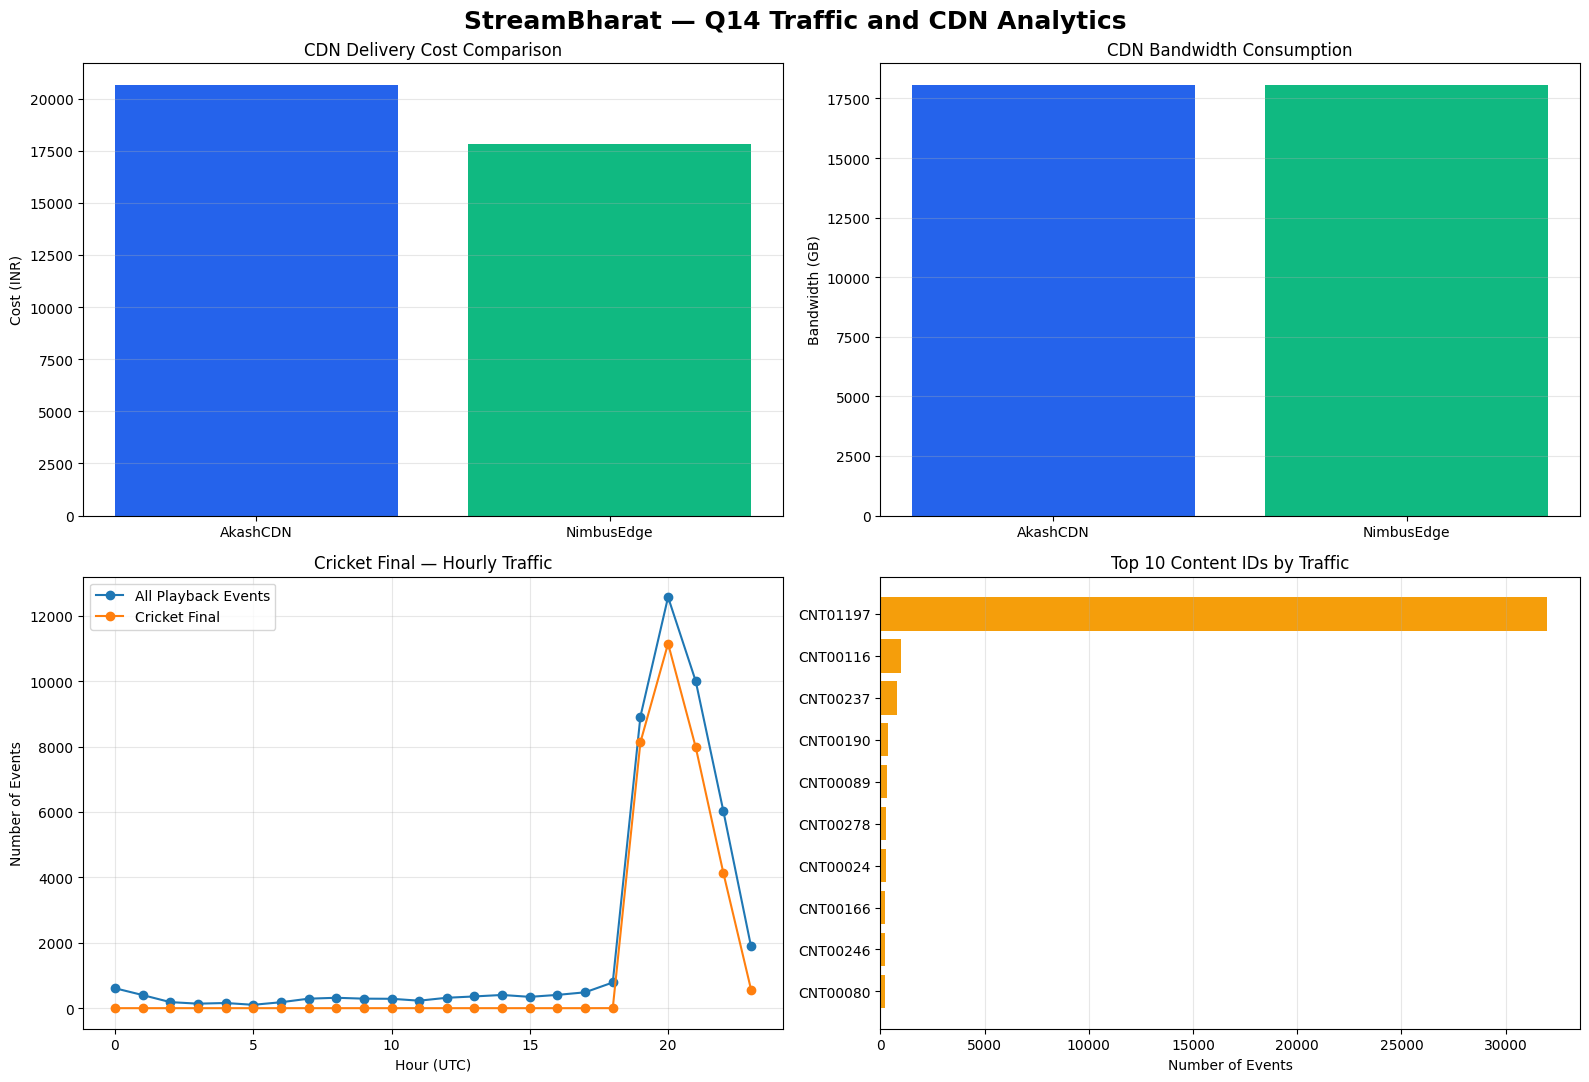

Dashboard saved successfully!


In [93]:
import matplotlib.pyplot as plt
import pandas as pd

# Convert Spark DataFrames to Pandas
cost_pd = cdn_cost_summary.toPandas()
bandwidth_pd = cdn_bandwidth.toPandas()
hourly_pd = hourly_traffic.toPandas()
content_pd = optimized_counts.limit(10).toPandas()

# Create dashboard
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. CDN Cost Comparison
axes[0, 0].bar(
    cost_pd["cdn"],
    cost_pd["total_cost_inr"],
    color=["#2563eb", "#10b981"]
)
axes[0, 0].set_title("CDN Delivery Cost Comparison")
axes[0, 0].set_ylabel("Cost (INR)")
axes[0, 0].grid(axis="y", alpha=0.3)

# 2. CDN Bandwidth Comparison
axes[0, 1].bar(
    bandwidth_pd["cdn"],
    bandwidth_pd["bandwidth_gb"],
    color=["#2563eb", "#10b981"]
)
axes[0, 1].set_title("CDN Bandwidth Consumption")
axes[0, 1].set_ylabel("Bandwidth (GB)")
axes[0, 1].grid(axis="y", alpha=0.3)

# 3. Cricket Final Hourly Traffic
hourly_pd = hourly_pd.sort_values("hour")

axes[1, 0].plot(
    hourly_pd["hour"],
    hourly_pd["total_events"],
    marker="o",
    label="All Playback Events"
)
axes[1, 0].plot(
    hourly_pd["hour"],
    hourly_pd["cricket_events"],
    marker="o",
    label="Cricket Final"
)
axes[1, 0].set_title("Cricket Final — Hourly Traffic")
axes[1, 0].set_xlabel("Hour (UTC)")
axes[1, 0].set_ylabel("Number of Events")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# 4. Top 10 Content by Traffic
content_pd = content_pd.sort_values("total_events")

axes[1, 1].barh(
    content_pd["content_id"],
    content_pd["total_events"],
    color="#f59e0b"
)
axes[1, 1].set_title("Top 10 Content IDs by Traffic")
axes[1, 1].set_xlabel("Number of Events")
axes[1, 1].grid(axis="x", alpha=0.3)

plt.suptitle(
    "StreamBharat — Q14 Traffic and CDN Analytics",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()

# Save dashboard to Google Drive
plt.savefig(
    f"{OUTPUT}/q14_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Dashboard saved successfully!")

In [92]:
# Save CDN bandwidth
cdn_bandwidth.write.mode("overwrite").parquet(
    f"{OUTPUT}/q14_cdn_bandwidth"
)

# Save CDN cost summary
cdn_cost_summary.write.mode("overwrite").parquet(
    f"{OUTPUT}/q14_cdn_cost_summary"
)

# Save detailed CDN costs
cdn_costs.write.mode("overwrite").parquet(
    f"{OUTPUT}/q14_cdn_cost_details"
)

# Save cricket final traffic analysis
hourly_traffic.write.mode("overwrite").parquet(
    f"{OUTPUT}/q14_hourly_traffic"
)

# Save skew-optimized content counts
optimized_counts.write.mode("overwrite").parquet(
    f"{OUTPUT}/q14_optimized_content_counts"
)

print("All Q14 results saved successfully!")

All Q14 results saved successfully!
